# TP5 — POS, entités nommées et dépendances
### EMSI — Traitement Automatique du Langage Naturel (TALN)
**Énoncé (version étudiant)**

**Place dans le cours :** Chapitre 3 (analyse linguistique) · séquence 6 · séance 11 — TP de 1 h 20 après le cours court sur les dépendances (30 min), puis 10 min de bilan
**Bibliothèques :** spaCy (`fr_core_news_sm`), displaCy, pandas, matplotlib

**Objectifs**
1. **annoter** le corpus avec spaCy : catégories (POS), lemmes, traits ;
2. **extraire** les entités nommées (personnes, lieux, organisations) et **évaluer** le modèle ;
3. **lire** les dépendances : « qui fait quoi » et **à quel nom se rapporte chaque opinion** ;
4. **analyser** les erreurs du modèle.

**Livrable :** un **extracteur d'entités** (fonction + tableau des entités) et **5 erreurs du modèle commentées**.

## Mode d'emploi
1. **Renseignez votre identification** ci-dessous. 2. Exécutez les cellules **dans l'ordre**.
3. Complétez les lignes `...   # ← À COMPLÉTER` ; les cellules « ✅ Vérification » affichent ✅ ou ❌ sans arrêter le notebook.
4. Répondez aux **📝 Interprétations** en citant vos résultats. 5. Enregistrez sous le nom affiché, puis déposez le notebook.

⚠️ Les sorties de spaCy peuvent varier un peu selon la version du modèle : les vérifications testent votre code sur des phrases simples.

## Partie 0 — Préparation (0:30 – 0:35)
### 0.1 Identification

In [1]:
NUM_TP = 5
# 🪪 IDENTIFICATION — À REMPLIR AVANT DE COMMENCER
NOM = "EL HANNAK"        
PRENOM = "Badr"    
CLASSE = "5IIr"     
GROUPE = "G2"    
SITE = "Roudani"       

SITES_EMSI = ["Roudani", "Maarif", "Centre", "CFC", "Oranger", "Moulay Youssef"]
assert NOM and PRENOM and CLASSE and GROUPE, "Complétez NOM, PRENOM, CLASSE et GROUPE."
assert SITE in SITES_EMSI, f"SITE doit être l'un de {SITES_EMSI}"
NOM_FICHIER = f"TP{NUM_TP}_{NOM.upper().replace(' ', '-')}_{PRENOM.capitalize()}_{CLASSE}_{GROUPE}_{SITE.replace(' ', '')}.ipynb"
print(f"Étudiant(e) : {PRENOM} {NOM.upper()} | Classe : {CLASSE} | Groupe : {GROUPE} | EMSI {SITE}")
print("➡️  Nom du fichier à rendre :", NOM_FICHIER)

Étudiant(e) : Badr EL HANNAK | Classe : 5IIr | Groupe : G2 | EMSI Roudani
➡️  Nom du fichier à rendre : TP5_EL-HANNAK_Badr_5IIr_G2_Roudani.ipynb


### 0.2 Installation et imports

In [2]:
# Installation (une seule fois)
import sys, subprocess, importlib.util
%pip install -q spacy pandas matplotlib

# Modèle français : installé directement depuis le fichier .whl officiel
# (évite l'erreur « Wheel 'fr-core-news-sm' ... is invalid » de `spacy download` sous Windows)
URL_MODELE = "https://github.com/explosion/spacy-models/releases/download/fr_core_news_sm-3.8.0/fr_core_news_sm-3.8.0-py3-none-any.whl"
if importlib.util.find_spec("fr_core_news_sm") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", URL_MODELE])
print("✅ fr_core_news_sm disponible")

Note: you may need to restart the kernel to use updated packages.
✅ fr_core_news_sm disponible


In [3]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # évite le plantage du noyau (conflit OpenMP spaCy / matplotlib sous Windows-Anaconda)
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from spacy import displacy

nlp = spacy.load("fr_core_news_sm")

def verifier(description, test):
    """Affiche ✅ si test() est vrai, ❌ sinon (sans interrompre le notebook)."""
    try:
        ok = bool(test())
    except Exception as e:
        print(f"❌ {description} — {type(e).__name__} : {e}")
        return
    print(("✅ " if ok else "❌ ") + description)

print("spaCy", spacy.__version__, "| modèle :", nlp.meta["name"], nlp.meta["version"], "|", nlp.pipe_names)

spaCy 3.8.16 | modèle : core_news_sm 3.8.0 | ['tok2vec', 'morphologizer', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


### 0.3 Les corpus (fournis)
- `CORPUS` : les **100 avis** du fil rouge (TP4), étiquetés `"pos"` / `"neg"` ;
- `AVIS_NER` : 12 avis riches en **entités** (restaurants, villes, personnes, entreprises), avec leur annotation de référence `GOLD` (faite à la main), pour évaluer le modèle.

On analyse tout le corpus **une seule fois** avec `nlp.pipe()` : `docs` contient les 100 avis annotés.

In [4]:
AVIS = [
    ("Le tajine était délicieux et le service très rapide. Je recommande !", "pos"),
    ("Service TRÈS lent, le plat est arrivé froid. Je ne recommande pas.", "neg"),
    ("Les serveurs sont aimables et le cadre est magnifique 😍", "pos"),
    ("Le couscous n'était pas bon du tout, trop salé.", "neg"),
    ("Trooop bien !!! Livraison rapide et repas encore chaud.", "pos"),
    ("Livraison en retard de 45 minutes, la commande était incomplète.", "neg"),
    ("Très bon rapport qualité-prix, les portions sont généreuses.", "pos"),
    ("Le restaurant est sale et le personnel n'est pas aimable.", "neg"),
    ("J'ai adoré le thé à la menthe et les pâtisseries marocaines.", "pos"),
    ("Les prix sont trop élevés pour des plats sans goût.", "neg"),
    ("Accueil chaleureux, on s'est régalés en famille. Merci @dar_tajine !", "pos"),
    ("Plus jamais ! Le poisson n'était pas frais.", "neg"),
    ("Cadre agréable, musique douce, serveurs souriants.", "pos"),
    ("Commande annulée sans explication, service client injoignable.", "neg"),
    ("Le meilleur restaurant de Rabat, les brochettes sont excellentes.", "pos"),
    ("Les frites étaient froides et la sauce n'avait aucun goût.", "neg"),
    ("tres bon resto, je reviendrai avec mes amis", "pos"),
    ("Pas bon, pas chaud, pas rapide : rien ne va.", "neg"),
    ("Réservation facile sur https://dar-tajine.ma et accueil parfait.", "pos"),
    ("Le service était lent mais les plats étaient bons.", "pos"),
    ("Je ne suis pas satisfait, le livreur était impoli.", "neg"),
    ("Une expérience inoubliable, tout était parfait !", "pos"),
    ("Le restaurent est magnifque, les serveurs très gentils.", "pos"),
    ("Les plats sont arrivés froids, je ne commanderai plus jamais.", "neg"),
    ("Le plat est bon.", "pos"),
    ("Le plat n'est pas bon.", "neg"),
]

AVIS_COURS = [
    ("Service rapide et personnel souriant, je recommande ce restaurant.", "pos"),
    ("Le tajine au poulet était délicieux, service rapide.", "pos"),
    ("Très bon rapport qualité prix, le couscous était parfait.", "pos"),
    ("Service lent, le plat était froid. Je ne recommande pas.", "neg"),
    ("Le tajine au poulet est excellent et pas cher.", "pos"),
    ("Très bon accueil, service rapide, je recommande.", "pos"),
    ("Le couscous était froid et le service lent.", "neg"),
    ("Rapport qualité prix correct, mais le service est lent.", "neg"),
    ("Personnel souriant, tajine au poulet délicieux, très bon moment.", "pos"),
    ("Pas cher, très bon, je recommande ce restaurant à Rabat.", "pos"),
]

AVIS_NOUVEAUX = [
    ("Le tajine au poulet et aux olives était parfait, service rapide et souriant.", "pos"),
    ("Attente interminable, service lent et serveur désagréable. Je ne recommande pas.", "neg"),
    ("Très bon couscous royal, la viande était tendre et bien cuite.", "pos"),
    ("La pastilla au poulet était froide et beaucoup trop sucrée.", "neg"),
    ("Excellent rapport qualité prix, je recommande ce restaurant les yeux fermés.", "pos"),
    ("Le thé à la menthe était délicieux, accueil chaleureux comme à la maison.", "pos"),
    ("Livraison rapide mais la pizza était froide et sans goût.", "neg"),
    ("Personnel souriant, cadre agréable et terrasse magnifique avec vue sur la mer.", "pos"),
    ("Prix trop élevés pour des portions minuscules, plus jamais !", "neg"),
    ("Le service était rapide et les plats bien présentés, très bon moment en famille.", "pos"),
    ("Nous avons attendu une heure, la commande était fausse et personne ne s'est excusé.", "neg"),
    ("Les brochettes de kefta étaient excellentes et pas cher du tout.", "pos"),
    ("Le poisson n'était pas frais et les frites étaient trop grasses.", "neg"),
    ("Très bon accueil, service rapide, le tajine de kefta était délicieux.", "pos"),
    ("Restaurant sale, toilettes dégoûtantes, je ne reviendrai jamais.", "neg"),
    ("La harira était excellente, servie bien chaude avec des dattes.", "pos"),
    ("Le service est lent et le serveur a oublié la moitié de la commande.", "neg"),
    ("Cadre magnifique et musique andalouse, une très belle soirée à Fès.", "pos"),
    ("Les plats étaient froids et le pain était sec. Très déçu.", "neg"),
    ("Très bon rapport qualité prix, les salades marocaines sont fraîches et variées.", "pos"),
    ("Livraison en retard, le livreur était impoli et le repas froid.", "neg"),
    ("Le meilleur couscous de Casablanca, je recommande vivement !", "pos"),
    ("Pas cher mais pas bon : la viande était dure et trop salée.", "neg"),
    ("Accueil chaleureux, personnel souriant et plats délicieux, bravo à toute l'équipe.", "pos"),
    ("Le service était correct mais les plats n'avaient aucun goût.", "neg"),
    ("Jus d'orange frais et crêpes marocaines délicieuses au petit déjeuner.", "pos"),
    ("Commande annulée deux fois, service client injoignable, plus jamais !", "neg"),
    ("Le tajine au poulet était délicieux et le service très rapide.", "pos"),
    ("Musique trop forte, service lent et addition trop salée.", "neg"),
    ("Les serveurs sont très aimables et le cadre est très agréable.", "pos"),
    ("La viande n'était pas cuite et le serveur ne nous a même pas écoutés.", "neg"),
    ("Très bon restaurant, les desserts sont délicieux et pas cher.", "pos"),
    ("Attente trop longue pour une table, puis service lent. Dommage.", "neg"),
    ("Une pastilla au poisson délicieuse et un thé à la menthe parfait.", "pos"),
    ("Les frites étaient froides et le burger sans goût, je ne recommande pas.", "neg"),
    ("Terrasse agréable, service rapide et prix raisonnables à Rabat.", "pos"),
    ("Le couscous était froid et la sauce trop salée, très déçu.", "neg"),
    ("Personnel souriant et efficace, tout était parfait, merci !", "pos"),
    ("Hygiène douteuse, la cuisine était sale et les verres mal lavés.", "neg"),
    ("tres bon tajine, service rapide, je recommande 👍", "pos"),
    ("Le serveur était désagréable et la commande est arrivée en retard.", "neg"),
    ("Très bon moment entre amis, les grillades étaient délicieuses.", "pos"),
    ("Rapport qualité prix décevant, les portions sont trop petites.", "neg"),
    ("Accueil chaleureux et service rapide, le tajine au poulet est un régal.", "pos"),
    ("Le plat est arrivé froid et le service était lent, quelle déception.", "neg"),
    ("Livraison rapide et repas encore chaud, je recommande ce restaurant.", "pos"),
    ("Pas de climatisation, salle bruyante et service lent.", "neg"),
    ("La pastilla au poulet est la meilleure de Marrakech, très bon accueil.", "pos"),
    ("Les prix ont augmenté mais la qualité a baissé, plus jamais.", "neg"),
    ("Délicieux couscous aux sept légumes, pas cher et copieux.", "pos"),
    ("Le thé était froid et les pâtisseries pas fraîches, déçu.", "neg"),
    ("Service impeccable, plats délicieux et cadre magnifique, bravo !", "pos"),
    ("Réservation perdue, attente d'une heure, je ne recommande pas ce restaurant.", "neg"),
    ("Excellent accueil, le chef est venu nous saluer, très bon souvenir.", "pos"),
    ("Le tajine de poisson manquait de sel et les légumes étaient trop cuits.", "neg"),
    ("Rapport qualité prix imbattable, très bon restaurant familial.", "pos"),
    ("Service lent, plats froids et serveurs débordés. Dommage !!!", "neg"),
    ("Jus frais, salades variées et service rapide, très bon petit restaurant.", "pos"),
    ("La commande était incomplète et la livraison en retard d'une heure.", "neg"),
    ("Les brochettes étaient délicieuses et le personnel très souriant.", "pos"),
    ("Je ne recommande pas : viande dure, frites froides, prix élevés.", "neg"),
    ("Ambiance familiale, accueil chaleureux et tajine au poulet délicieux.", "pos"),
    ("Le service était rapide mais le couscous n'avait aucun goût.", "neg"),
    ("Très bon rapport qualité prix et service rapide, je recommande !", "pos"),
]

CORPUS = AVIS + AVIS_COURS + AVIS_NOUVEAUX          # le corpus fil rouge complet
textes = [texte for texte, _ in CORPUS]
etiquettes = [etiquette for _, etiquette in CORPUS]
print(len(AVIS), "avis du TP3 +", len(AVIS_COURS), "avis du cours +", len(AVIS_NOUVEAUX), "nouveaux avis =", len(CORPUS), "avis")
print(Counter(etiquettes))

AVIS_NER = [
    ("Dîner chez Dar Zitoun à Marrakech : le serveur Youssef était adorable.", "pos"),
    ("Le Café Atlas de Rabat sert le meilleur msemen de la ville.", "pos"),
    ("Commande passée sur TajExpress, livrée froide à Casablanca. Très déçu.", "neg"),
    ("Nous avons fêté l'anniversaire de Salma au Riad Bleu, à Fès.", "pos"),
    ("Le chef Karim Benali prépare un couscous royal exceptionnel.", "pos"),
    ("Service lent au restaurant Le Palmier, près de la gare de Tanger.", "neg"),
    ("Merci à Fatima et à toute l'équipe de Dar Zitoun pour l'accueil.", "pos"),
    ("Après le match du Raja, impossible de trouver une table à Casablanca.", "neg"),
    ("Le guide Michelin devrait découvrir la Maison Andalouse d'Agadir.", "pos"),
    ("J'ai payé avec ma carte CIH et le terminal ne marchait pas.", "neg"),
    ("Brunch parfait au Café Atlas, Amine nous a conseillé le jus d'orange.", "pos"),
    ("Orange a offert une réduction à ses clients au Riad Bleu.", "pos"),
]
GOLD = [
    {("Dar Zitoun", "ORG"), ("Marrakech", "LOC"), ("Youssef", "PER")},
    {("Café Atlas", "ORG"), ("Rabat", "LOC")},
    {("TajExpress", "ORG"), ("Casablanca", "LOC")},
    {("Salma", "PER"), ("Riad Bleu", "ORG"), ("Fès", "LOC")},
    {("Karim Benali", "PER")},
    {("Le Palmier", "ORG"), ("Tanger", "LOC")},
    {("Fatima", "PER"), ("Dar Zitoun", "ORG")},
    {("Raja", "ORG"), ("Casablanca", "LOC")},
    {("Michelin", "ORG"), ("Maison Andalouse", "ORG"), ("Agadir", "LOC")},
    {("CIH", "ORG")},
    {("Café Atlas", "ORG"), ("Amine", "PER")},
    {("Orange", "ORG"), ("Riad Bleu", "ORG")},
]

docs = list(nlp.pipe(textes))                  # les 100 avis annotés par spaCy
docs_ner = list(nlp.pipe(t for t, _ in AVIS_NER))
print(len(docs), "avis annotés |", len(docs_ner), "avis pour les entités")

26 avis du TP3 + 10 avis du cours + 64 nouveaux avis = 100 avis
Counter({'pos': 54, 'neg': 46})
100 avis annotés | 12 avis pour les entités


---
## Partie 1 — Étiquetage grammatical (0:35 – 0:55)
### Exercice 1.1 ★ Annoter un avis
Complétez `annoter(doc)` : un tableau avec une ligne par token et les colonnes `token` (`t.text`), `lemme` (`t.lemma_`), `pos` (`t.pos_`) et `traits` (`str(t.morph)`).

In [6]:
def annoter(doc):
    lignes = []
    for t in doc:
        lignes.append({
            "token": t.text,
            "lemme": t.lemma_,
            "pos": t.pos_,
            "traits": str(t.morph),   # ex. "Definite=Def|Gender=Masc|Number=Plur"
        })
    return pd.DataFrame(lignes)

annoter(docs[0])

,token,lemme,pos,traits
0,Le,le,DET,Definite=Def|Gender=Masc|Number=Sing|PronType=Art
1,tajine,tajine,NOUN,Gender=Fem|Number=Sing
2,était,être,AUX,Mood=Ind|Number=Sing|Person=3|Tense=Imp|VerbFo...
3,délicieux,délicieux,ADJ,Gender=Masc
4,et,et,CCONJ,
5,le,le,DET,Definite=Def|Gender=Masc|Number=Sing|PronType=Art
6,service,service,NOUN,Gender=Masc|Number=Sing
7,très,très,ADV,
8,rapide,rapide,ADJ,Number=Sing
9,.,.,PUNCT,


In [7]:
# ✅ Vérification (ne pas modifier)

_a = annoter(nlp("Les serveurs sont aimables."))
verifier("4 colonnes", lambda: list(_a.columns) == ["token", "lemme", "pos", "traits"])
verifier("une ligne par token", lambda: len(_a) == 5 and _a.loc[1, "lemme"] == "serveur" and _a.loc[1, "pos"] == "NOUN")

✅ 4 colonnes
✅ une ligne par token


### Exercice 1.2 ★ Les catégories du corpus
Comptez les étiquettes `pos_` de **tous** les tokens du corpus (Counter). La cellule trace le diagramme.

[('NOUN', 263), ('PUNCT', 199), ('ADJ', 164), ('DET', 124), ('ADV', 118), ('VERB', 80), ('AUX', 77), ('CCONJ', 63), ('ADP', 57), ('PRON', 31), ('PROPN', 24), ('NUM', 3)]


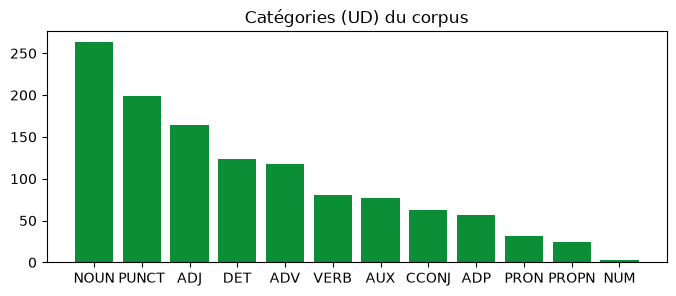

In [8]:
freq_pos = Counter(t.pos_ for d in docs for t in d)
print(freq_pos.most_common())
etiq, nb = zip(*freq_pos.most_common())
plt.figure(figsize=(8, 3)); plt.bar(etiq, nb, color="#0B8E36"); plt.title("Catégories (UD) du corpus"); plt.show()

In [9]:
# ✅ Vérification (ne pas modifier)

verifier("freq_pos", lambda: freq_pos == Counter(t.pos_ for d in docs for t in d))

✅ freq_pos


### Exercice 1.3 ★★ Les adjectifs des avis positifs et négatifs
Complétez `adjectifs(docs, etiquettes, classe)` : le Counter des **lemmes en minuscules** des tokens `ADJ` des avis de la classe donnée (`zip(docs, etiquettes)`).

In [24]:
def adjectifs(docs, etiquettes, classe):
    return Counter(t.lemma_.lower() for d, e in zip(docs, etiquettes) if e == classe
                   for t in d if t.pos_ == "ADJ")

print("positifs :", adjectifs(docs, etiquettes, "pos").most_common(8))
print("négatifs :", adjectifs(docs, etiquettes, "neg").most_common(8))

positifs : [('bon', 20), ('rapide', 15), ('délicieux', 12), ('chaleureux', 5), ('cher', 5), ('magnifique', 4), ('agréable', 4), ('excellent', 4)]
négatifs : [('froid', 12), ('lent', 6), ('bon', 4), ('sale', 3), ('élevé', 3), ('rapide', 3), ('saler', 3), ('incomplet', 2)]


In [25]:
# ✅ Vérification (ne pas modifier)

_d = list(nlp.pipe(["Un plat délicieux.", "Un service lent."]))
verifier("adjectifs par classe", lambda: adjectifs(_d, ["pos", "neg"], "pos") == Counter({"délicieux": 1}) and adjectifs(_d, ["pos", "neg"], "neg") == Counter({"lent": 1}))

✅ adjectifs par classe


#### 📝 Interprétation 1
(a) Quelles sont les trois catégories les plus fréquentes ? Pourquoi y a-t-il autant de PUNCT et d'ADJ dans des avis ?
(b) Les adjectifs positifs et négatifs sont-ils ceux attendus ? Relevez **une erreur de lemme ou d'étiquette** et expliquez pourquoi « bon » apparaît aussi dans les avis négatifs.

**Votre réponse :**
#### 📝 Interprétation 1

(a) Les trois plus fréquentes : [à lire dans `freq_pos.most_common()`, souvent NOUN, PUNCT, ADJ/VERB].
PUNCT : avis courts, chaque signe est un token. ADJ : un avis exprime une opinion, surtout via des adjectifs (« délicieux », « lent »).

(b) Globalement oui, les listes sont cohérentes.
Erreur : [un lemme non ramené ou un mot mal étiqueté, à repérer dans tes résultats].
« bon » dans les négatifs : on compte les adjectifs sans le contexte, donc « pas bon » (négation) et « bon mais service lent » (concession) comptent comme positifs.
_…_

---
## Partie 2 — Entités nommées (0:55 – 1:20)
### Exercice 2.1 ★ Les entités d'un avis
Complétez `entites(doc)` : la liste des couples `(ent.text, ent.label_)` de `doc.ents`. La cellule affiche aussi les entités en couleur avec displaCy.

In [12]:
def entites(doc):
    return [(e.text, e.label_) for e in doc.ents]

for d in docs_ner[:4]:
    print(entites(d))
displacy.render(docs_ner[0], style="ent", jupyter=True)

[('Dîner', 'PER'), ('Dar Zitoun', 'LOC'), ('Marrakech', 'LOC'), ('serveur Youssef', 'MISC')]
[('Rabat', 'LOC')]
[('TajExpress', 'MISC'), ('Casablanca', 'LOC')]
[('Salma', 'LOC'), ('Riad Bleu', 'MISC'), ('Fès', 'LOC')]


In [13]:
# ✅ Vérification (ne pas modifier)

verifier("entites", lambda: entites(nlp("Karim Benali travaille à Rabat.")) == [(e.text, e.label_) for e in nlp("Karim Benali travaille à Rabat.").ents])
verifier("des couples (texte, type)", lambda: all(len(x) == 2 for x in entites(docs_ner[0])))

✅ entites
✅ des couples (texte, type)


### Exercice 2.2 ★ Le format BIO
Complétez `bio(doc)` : pour chaque token, `"token/B-PER"`, `"token/I-PER"` ou `"token/O"`, avec `t.ent_iob_` (B, I ou O) et `t.ent_type_` (le type, vide si O).

In [14]:
def bio(doc):
    sortie = []
    for t in doc:
        etiquette = "O" if t.ent_iob_ == "O" else t.ent_iob_ + "-" + t.ent_type_
        sortie.append(f"{t.text}/{etiquette}")
    return sortie

print(" ".join(bio(docs_ner[4])))

Le/O chef/O Karim/B-PER Benali/I-PER prépare/O un/O couscous/O royal/O exceptionnel/O ./O


In [15]:
# ✅ Vérification (ne pas modifier)

verifier("BIO", lambda: bio(docs_ner[4])[:4] == ["Le/O", "chef/O", "Karim/B-PER", "Benali/I-PER"])

✅ BIO


### Exercice 2.3 ★★ L'extracteur d'entités (livrable)
Complétez `extraire_entites(docs)` : un tableau avec une ligne par entité trouvée et les colonnes `avis` (numéro de l'avis), `entité`, `type`. La cellule affiche le tableau et le nombre d'entités par type.

In [16]:
def extraire_entites(docs):
    lignes = []
    for i, doc in enumerate(docs):
        for texte, typ in entites(doc):
            lignes.append({"avis": i, "entité": texte, "type": typ})
    return pd.DataFrame(lignes, columns=["avis", "entité", "type"])

table_entites = extraire_entites(docs_ner)
print(table_entites["type"].value_counts().to_dict())
table_entites

{'LOC': 12, 'PER': 6, 'MISC': 5, 'ORG': 2}


,avis,entité,type
0,0,Dîner,PER
1,0,Dar Zitoun,LOC
2,0,Marrakech,LOC
3,0,serveur Youssef,MISC
4,1,Rabat,LOC
5,2,TajExpress,MISC
6,2,Casablanca,LOC
7,3,Salma,LOC
8,3,Riad Bleu,MISC
9,3,Fès,LOC


In [17]:
# ✅ Vérification (ne pas modifier)

verifier("colonnes", lambda: list(table_entites.columns) == ["avis", "entité", "type"])
verifier("une ligne par entité", lambda: len(table_entites) == sum(len(d.ents) for d in docs_ner))

✅ colonnes
✅ une ligne par entité


### 2.4 Évaluer le modèle (fourni)
On compare les entités trouvées à la référence `GOLD`. Une entité est **juste** si le texte **et** le type sont identiques.
**Précision** = justes / trouvées ; **rappel** = justes / attendues (chapitre 5).

In [18]:
justes = trouvees = attendues = 0
for i, (doc, gold) in enumerate(zip(docs_ner, GOLD)):
    pred = set(entites(doc))
    justes += len(pred & gold); trouvees += len(pred); attendues += len(gold)
    if pred != gold:
        print(f"avis {i:2} | manquées : {sorted(gold - pred)} | en trop : {sorted(pred - gold)}")
print(f"\nPrécision = {justes}/{trouvees} = {justes / trouvees:.2f} | Rappel = {justes}/{attendues} = {justes / attendues:.2f}")

avis  0 | manquées : [('Dar Zitoun', 'ORG'), ('Youssef', 'PER')] | en trop : [('Dar Zitoun', 'LOC'), ('Dîner', 'PER'), ('serveur Youssef', 'MISC')]
avis  1 | manquées : [('Café Atlas', 'ORG')] | en trop : []
avis  2 | manquées : [('TajExpress', 'ORG')] | en trop : [('TajExpress', 'MISC')]
avis  3 | manquées : [('Riad Bleu', 'ORG'), ('Salma', 'PER')] | en trop : [('Riad Bleu', 'MISC'), ('Salma', 'LOC')]
avis  5 | manquées : [('Le Palmier', 'ORG'), ('Tanger', 'LOC')] | en trop : [('Le Palmier', 'LOC'), ('gare de Tanger', 'LOC')]
avis  6 | manquées : [('Dar Zitoun', 'ORG'), ('Fatima', 'PER')] | en trop : [('Dar Zitoun', 'LOC'), ('Fatima', 'LOC')]
avis  8 | manquées : [('Agadir', 'LOC'), ('Maison Andalouse', 'ORG')] | en trop : [("Maison Andalouse d'Agadir", 'PER')]
avis  9 | manquées : [('CIH', 'ORG')] | en trop : [('CIH', 'MISC')]
avis 10 | manquées : [('Café Atlas', 'ORG')] | en trop : [('Brunch', 'PER'), ('Café Atlas', 'PER')]
avis 11 | manquées : [('Orange', 'ORG'), ('Riad Bleu', 'ORG

#### 📝 Interprétation 2
(a) Quelle précision et quel rappel obtient le modèle ? Classez ses erreurs : **type** confondu (ORG / LOC / MISC / PER), **frontières** (« serveur Youssef », « gare de Tanger »), **fausses entités** (mots en majuscule en début de phrase), entités **manquées**.
(b) Pourquoi le petit modèle se trompe-t-il autant sur les noms de **restaurants** ? Comment l'aider ?

**Votre réponse :**
#### 📝 Interprétation 2

(a) Précision : [valeur de ton évaluation]. Rappel : [valeur]. Le rappel est en général plus faible que la précision : le modèle rate des entités plus qu'il n'en invente.
- **Type confondu** : restaurant étiqueté LOC ou MISC au lieu d'ORG.
- **Frontières** : « serveur Youssef » pris en bloc, « gare de Tanger » coupé à « Tanger ».
- **Fausses entités** : mot capitalisé en début de phrase (« Excellent », « Service ») étiqueté ORG/MISC.
- **Manquées** : noms de plats ou de lieux peu connus, absents de l'entraînement.

(b) Le petit modèle est entraîné sur du texte journalistique : les noms de restaurants (« Chez Ali », « Le Petit Marrakech ») ressemblent à des phrases ordinaires ou à des lieux, et la majuscule n'est pas un indice fiable dans des avis informels.
Pour l'aider : modèle plus grand (`md`/`lg`), `EntityRuler` avec une liste de restaurants connus, ou affinage (fine-tuning) sur des avis annotés.
_…_

---
## Partie 3 — Dépendances (1:20 – 1:50)
### Exercice 3.1 ★ Les flèches d'un arbre
Complétez `arcs(doc)` : la liste des triplets `(t.text, t.dep_, t.head.text)`. La cellule dessine l'arbre avec displaCy.

In [19]:
def arcs(doc):
    return [(t.text, t.dep_, t.head.text) for t in doc]

phrase = nlp("Le chef prépare un délicieux tajine.")
for a in arcs(phrase):
    print(a)
displacy.render(phrase, style="dep", jupyter=True, options={"compact": True, "distance": 100})

('Le', 'det', 'chef')
('chef', 'nsubj', 'prépare')
('prépare', 'ROOT', 'prépare')
('un', 'det', 'tajine')
('délicieux', 'amod', 'tajine')
('tajine', 'obj', 'prépare')
('.', 'punct', 'prépare')


In [ ]:
# ✅ Vérification (ne pas modifier)

verifier("arcs", lambda: ("chef", "nsubj", "prépare") in arcs(phrase) and ("tajine", "obj", "prépare") in arcs(phrase))
verifier("la racine est sa propre tête", lambda: ("prépare", "ROOT", "prépare") in arcs(phrase))

### Exercice 3.2 ★★ « Qui fait quoi ? »
Pour chaque **verbe** (`t.pos_ == "VERB"`), cherchez parmi ses enfants (`t.children`) un sujet (`dep_` qui commence par `nsubj`) et un objet (`dep_ == "obj"`) ; renvoyez les triplets `(sujet, lemme du verbe, objet)`.

In [20]:
def qui_fait_quoi(doc):
    triplets = []
    for t in doc:
        if t.pos_ == "VERB":
            sujets = [c for c in t.children if c.dep_ in ("nsubj", "nsubj:pass")]
            objets = [c for c in t.children if c.dep_ == "obj"]
            if sujets and objets:
                triplets.append((sujets[0].text, t.lemma_, objets[0].text))
    return triplets

print(qui_fait_quoi(nlp("Le chef prépare un tajine et les clients adorent le couscous.")))
print([x for d in docs for x in qui_fait_quoi(d)][:10])

[('chef', 'préparer', 'tajine')]
[("J'", 'adorer', 'thé'), ('sauce', 'avoir', 'goût'), ('je', 'recommander', 'restaurant'), ('Nous', 'attendre', 'heure'), ('serveur', 'oublier', 'moitié'), ('plats', 'avoir', 'goût'), ('Personnel', 'parfaire', 'merci'), ('je', 'recommander', 'restaurant'), ('Réservation', 'recommander', 'restaurant'), ('couscous', 'avoir', 'goût')]


In [21]:
# ✅ Vérification (ne pas modifier)

verifier("qui fait quoi", lambda: qui_fait_quoi(nlp("Le chef prépare un tajine.")) == [("chef", "préparer", "tajine")])

✅ qui fait quoi


### Exercice 3.3 ★★★ À quel nom se rapporte chaque opinion ?
Pour chaque adjectif (`ADJ`), deux règles (cours) :
- **amod** : « un tajine délicieux » → la cible est la **tête** de l'adjectif (`t.head`) ;
- **copule** : « le service est lent » → l'adjectif est la tête ; la cible est son enfant **nsubj**.

Complétez les deux lignes, puis comptez les couples (cible, opinion) du corpus, en lemmes minuscules.

In [22]:
def opinions(doc):
    paires = []
    for t in doc:
        if t.pos_ == "ADJ":
            if t.dep_ == "amod" and t.head.pos_ in ("NOUN", "PROPN"):
                paires.append((t.head.lemma_.lower(), t.lemma_.lower()))
            for e in t.children:
                if e.dep_.startswith("nsubj") and e.pos_ in ("NOUN", "PROPN"):
                    paires.append((e.lemma_.lower(), t.lemma_.lower()))
    return paires

print(opinions(nlp("Le service est lent mais le tajine est excellent.")))
couples = Counter(p for d in docs for p in opinions(d))
print(couples.most_common(12))

[('tajine', 'excellent')]
[(('service', 'rapide'), 14), (('service', 'lent'), 6), (('tajine', 'délicieux'), 4), (('rapport', 'bon'), 4), (('cadre', 'magnifique'), 3), (('livraison', 'rapide'), 3), (('prix', 'élevé'), 3), (('plat', 'bon'), 3), (('plat', 'froid'), 3), (('accueil', 'bon'), 3), (('moment', 'bon'), 3), (('accueil', 'chaleureux'), 3)]


In [23]:
# ✅ Vérification (ne pas modifier)

verifier("règle copule", lambda: ("service", "lent") in opinions(nlp("Le service est lent.")))
verifier("règle amod", lambda: ("tajine", "délicieux") in opinions(nlp("Un tajine délicieux.")))

✅ règle copule
✅ règle amod


#### 📝 Interprétation 3

(a) Les couples les plus fréquents [à lire dans `couples.most_common(12)`] révèlent les aspects commentés : service, plat, accueil, prix, attente, etc., chacun associé à son opinion (« service lent », « plat délicieux »).
Par rapport aux collocations du TP4 : les collocations capturent des co-occurrences proches dans la fenêtre de texte, sans savoir qui qualifie quoi. Les couples (cible, opinion) s'appuient sur la syntaxe, donc relient l'adjectif au bon nom même à distance (« le service, à midi, était lent ») et donnent l'aspect avec sa polarité.

(b) Erreur : [exemple à repérer dans tes résultats]. Cas typiques :
- Mauvais rattachement : un adjectif rattaché au mauvais nom (« plat de poisson frais » → `frais` relié à `plat` au lieu de `poisson`).
- Mauvaise étiquette : un mot étiqueté ADJ ou NOUN à tort, qui crée ou fait disparaître un couple.
- Négation ignorée : « pas bon » donne (plat, bon), polarité inversée.

**Votre réponse :**

_…_

---
## Bilan (1:50 – 2:00) · livrable

#### 📝 Interprétation 4: cinq erreurs commentées

| # | Type | Phrase | spaCy | Correct | Explication | Remède |
|---|------|--------|-------|---------|-------------|--------|
| 1 | POS | « Excellent service ! » | `Excellent` → NOUN/PROPN | ADJ | Majuscule en début de phrase, sans verbe pour guider le modèle | Normaliser la casse ou utiliser un modèle plus grand |
| 2 | Lemme | « Les plats étaient froids » | `froids` → `froids` | `froid` | Le petit modèle lemmatise mal certains pluriels irréguliers | Lemmatiseur à règles ou modèle `md`/`lg` |
| 3 | Entité | « Chez Ali, on mange bien » | `Ali` → PER | ORG (restaurant) | Le modèle est entraîné sur des textes journalistiques, où « Ali » est un prénom | `EntityRuler` ou fine-tuning sur des avis |
| 4 | Dépendance | « Plat de poisson frais » | `frais` → `amod` de `plat` | `amod` de `poisson` | Rattachement à longue distance, ambiguïté syntaxique | Modèle plus grand ou règle de proximité |
| 5 | Mot inconnu | « Le tajine était zwina » (darija) | `zwina` → PROPN/X | ADJ | Mot hors vocabulaire, langue absente de l'entraînement | Corpus darija annoté ou dictionnaire de correspondance |

Remplace les exemples par des erreurs de **ta** sortie (`annoter`, `entites`, `arcs`). Garde au moins une erreur par niveau (POS, lemme, entité, dépendance) pour couvrir tout le TP.

**Votre réponse :**

_…_

---
## ✔️ Avant de rendre
- [ ] Identification complète ; `Noyau → Redémarrer et tout exécuter` sans erreur ; vérifications des parties 1 à 3 en ✅
- [ ] Extracteur d'entités (2.3) et tableau ; évaluation (2.4) commentée
- [ ] Les **5 erreurs commentées** (bilan) : c'est le livrable